# Лабораторная работа. Подготовка данных и обучение модели

Учебный год: 2026

__Цель:__ подготовить данные для задачи семантической сегментации (`Dataset` + `DataLoader`), визуализировать примеры, обучить модель с подходящей функцией ошибки, а также выполнить заготовки по формированию предсказаний и переводу масок в формат RLE.

## Структура данных

```
./
├── train/
│   ├── images/   # исходные изображения (*.jpg)
│   └── masks/    # маски сегментации (*.png), имена совпадают с изображениями
├── test/
│   └── images/   # тестовые изображения (*.jpg)
└── best_model.pt # веса обученной модели
```

Маска кодируется целыми числами: `1` — питомец, `2` — граница, `3` — фон.
Для бинарной сегментации её сводят к `1` (объект) и `0` (фон).

# 1. Подготовка данных

## 1.1 Импорт библиотек

In [16]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import pandas as pd

from PIL import Image
from torch.functional import F
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader

## 1.2 Пути к данным и число изображений

In [2]:
root_directory       = os.path.join(os.getcwd(), "./train/")
images_directory     = os.path.join(root_directory, "images")
masks_directory      = os.path.join(root_directory, "masks")
test_images_directory = os.path.join(os.getcwd(), "./test/images")

images_filenames = [i for i in os.listdir(images_directory)
                    if os.path.splitext(i)[-1] in (".png", ".jpg", ".jpeg", ".tiff", ".bmp", ".gif")]

print("n train images:", len(images_filenames))
print("n test  images:", len(os.listdir(test_images_directory)))

n train images: 5918
n test  images: 1742


## 1.3 Разбиение на train/val/test

In [3]:
random.seed(42)
random.shuffle(images_filenames)

n = len(images_filenames)
n_train = int(n * 0.8)
n_val   = int(n * 0.1)

train_images_filenames = images_filenames[:n_train]
val_images_filenames   = images_filenames[n_train:n_train + n_val]
test_images_filenames  = images_filenames[n_train + n_val:]

print("Train:", len(train_images_filenames))
print("Valid:", len(val_images_filenames))
print("Test :", len(test_images_filenames))

Train: 4734
Valid: 591
Test : 593


## 1.4 Класс `Dataset` и препроцессинг маски

- в `preprocess_mask` класс `2` (граница) заменяется на `0`, классы `1` и `3` — на `1`;
- в `__getitem__` изображение загружается как `RGB`, маска — из `masks/` с тем же именем (`.png`);
- метод возвращает пару `(image, mask)`.

In [4]:
class SegmentationDataset(Dataset):
    def __init__(self, images_filenames, images_directory, masks_directory, transforms=None):
        self.images_filenames = images_filenames
        self.images_directory = images_directory
        self.masks_directory  = masks_directory
        self.transforms = transforms

    def __len__(self):
        return len(self.images_filenames)

    def preprocess_mask(self, mask):
        mask = np.asarray(mask).astype(np.float32)
        mask[mask == 2.0] = 0.0
        mask[(mask == 1.0) | (mask == 3.0)] = 1.0
        return mask

    def __getitem__(self, idx):
        image_filename = self.images_filenames[idx]

        path_ = os.path.join(self.images_directory, image_filename)
        image = np.asarray(Image.open(path_).convert("RGB"))

        path_ = os.path.join(self.masks_directory, image_filename.replace(".jpg", ".png"))
        mask  = self.preprocess_mask(Image.open(path_))

        if self.transforms is not None:
            transformed = self.transforms(image=image, mask=mask)
            image = transformed["image"]
            mask  = transformed["mask"]

        return image, mask

## 1.5 Преобразования и создание датасетов

Для обучения используются аугментации, для валидации и теста — только изменение размера и нормализация (средние/дисперсии ImageNet).

In [5]:
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_transform = A.Compose([
    A.Resize(128, 128),
    A.ShiftScaleRotate(shift_limit=0.2, scale_limit=0.2, rotate_limit=10),
    A.Normalize(mean, std),
    ToTensorV2(),
])

test_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean, std),
    ToTensorV2(),
])

train_dataset = SegmentationDataset(train_images_filenames, images_directory, masks_directory, transforms=train_transform)
val_dataset   = SegmentationDataset(val_images_filenames,   images_directory, masks_directory, transforms=test_transform)
test_dataset  = SegmentationDataset(test_images_filenames,  images_directory, masks_directory, transforms=test_transform)

print(f"Train size: {len(train_dataset)}")
print(f"Valid size: {len(val_dataset)}")
print(f"Test size: {len(test_dataset)}")

Train size: 4734
Valid size: 591
Test size: 593


## 1.6 Сборка `DataLoader`

Обучающий загрузчик тасует данные (`shuffle=True`), валидационный и тестовый — нет.

In [35]:
BATCH = 16

train_loader = DataLoader(train_dataset, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH, shuffle=False)

x, y = next(iter(train_loader))
print("batch images:", x.shape, "| batch masks:", y.shape)

batch images: torch.Size([16, 3, 128, 128]) | batch masks: torch.Size([16, 128, 128])


## 1.7 Визуализация данных

После нормализации изображение нужно «денормализовать»: `image * std + mean`.

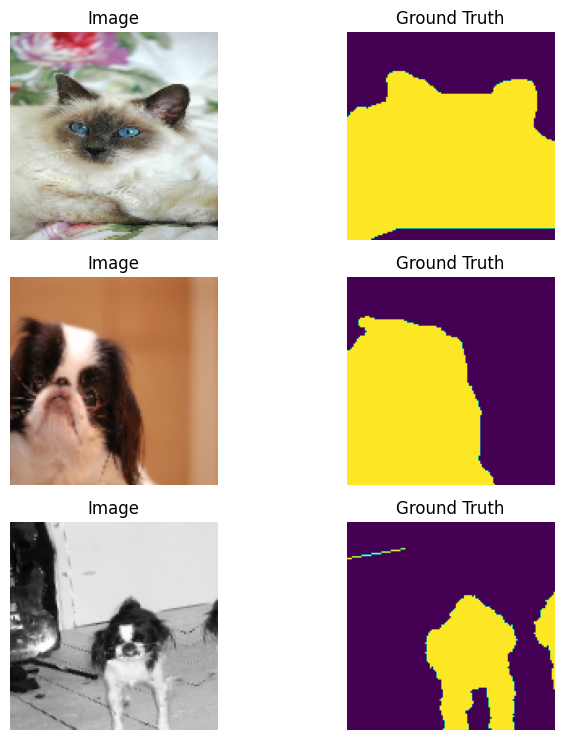

In [36]:
def visualize_dataset(dataset, samples=5, mean=mean, std=std):
    figure, ax = plt.subplots(nrows=samples, ncols=2, figsize=(8, samples * 2.5))

    for i in range(samples):
        image, mask = dataset[i]

        image = image.data.cpu().numpy().transpose((1, 2, 0))
        image = np.clip(image * std + mean, 0, 1)

        mask = np.clip(mask.data.cpu().numpy(), 0, 1)

        ax[i, 0].imshow(image); ax[i, 0].set_title("Image");        ax[i, 0].set_axis_off()
        ax[i, 1].imshow(mask);  ax[i, 1].set_title("Ground Truth"); ax[i, 1].set_axis_off()

    plt.tight_layout()
    plt.show()

visualize_dataset(train_dataset, samples=3)

# 2. Загрузка модели

Создаётся модель архитектуры `smp.UnetPlusPlus` с кодировщиком `efficientnet-b1` и загружаются сохранённые веса `best_model.pt` (если они есть). Если весов нет — модель создаётся без загрузки (`encoder_weights="imagenet"`) и обучается в разделе 3.

In [37]:
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = smp.UnetPlusPlus(encoder_name="efficientnet-b1", encoder_weights="imagenet", classes=1, activation=None)
model = model.to(device)

if os.path.exists("best_model.pt"):
    model.load_state_dict(torch.load("best_model.pt", map_location=device))
    print("weights loaded from best_model.pt")
else:
    print("best_model.pt not found, fine-tuning from ImageNet weights")

print("model params:", sum(p.numel() for p in model.parameters()) // 1000, "K")

Using device: cuda
weights loaded from best_model.pt
model params: 9075 K


# 3. Обучение модели (заготовка)

Для обучения необходимо:
1. Выбрать **подходящую функцию ошибки** для бинарной сегментации.
2. Задать метрику качества (например, `IoU`) и оптимизатор.
3. Написать цикл обучения с валидацией и сохранением лучших весов.

Заполните ячейки ниже (помечены `TODO`).

## 3.1 Функция ошибки (loss)

Для бинарной сегментации хорошо подходит `DiceLoss` из `segmentation_models_pytorch` (тесно связан с метрикой `IoU`), также применяют `BCEWithLogits` или их комбинацию (`smp.losses.DiceLoss` + какой-либо ещё). Выберите и настройте функцию ошибки — она должна принимать сырые логиты модели (`from_logits=True`), так как модель создана с `activation=None`.

Ожидаемый результат: `criterion(y_pred, y)` возвращает тензор-скаляр, например `criterion` = `DiceLoss()`.

In [38]:
import segmentation_models_pytorch as smp

criterion = (  # TODO: выберите подходящую функцию ошибки
    smp.losses.DiceLoss(smp.losses.BINARY_MODE, from_logits=True)
)

# проверка: считает ли функция ошибки скор на паре случайных тензоров нужной размерности
with torch.no_grad():
    y_pred_test = torch.randn(2, 1, 128, 128, device=device)
    y_test      = torch.randint(0, 2, (2, 1, 128, 128), device=device).float()
    print("loss value:", criterion(y_pred_test, y_test).item())

loss value: 0.4991164207458496


## 3.2 Метрика и оптимизатор

Метрика `IoU` (intersection over union) для бинарных масок считается через `smp.metrics`. Оптимизатор — например `AdamW` со скоростью обучения порядка `1e-3`.

In [40]:
def iou_score(output, target):
    # TODO: сожмите output по каналу (torch.squeeze(output, dim=1))
    # TODO: через smp.metrics.get_stats(output, target, mode='binary', threshold=0.5)
    #      и smp.metrics.iou_score(tp, fp, fn, tn, reduction="macro") верните IoU
    output = torch.squeeze(output, dim=1)
    tp, fp, fn, tn = smp.metrics.get_stats(output, target, mode='binary', threshold=0.5)
    iou_score = smp.metrics.iou_score(tp, fp, fn, tn, reduction="macro")
    return iou_score

optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)  # TODO: можно подобрать lr

## 3.3 Цикл обучения (заготовка)

Для каждой эпохи:
1. **Обучение** (`model.train()`): батч `(x, y)` → на устройство, `optimizer.zero_grad()`, `y_pred = model(x)`, `loss = criterion(y_pred, y)`, `loss.backward()`, `optimizer.step()`; накапливаются loss и метрика.
2. **Валидация** (`model.eval()` в режиме `torch.no_grad()`): те же шаги без обновления весов.
3. Сохранение весов в `best_model.pt`, если валидационный loss улучшился.

In [11]:
EPOCHS =  # TODO: число эпох
best_valid_loss = float("inf")

for epoch in range(EPOCHS):

    # ---- обучение ----
    model.train()
    train_loss, train_iou = 0.0, 0.0
    for x, y in train_loader:
        # TODO: x, y -> device; y -> float()
        # optimizer.zero_grad(); y_pred = model(x)
        # loss = criterion(y_pred, y); loss.backward(); optimizer.step()
        # накапливайте loss и iou_score
        pass
    train_loss /= len(train_loader)
    train_iou  /= len(train_loader)

    # ---- валидация ----
    model.eval()
    valid_loss, valid_iou = 0.0, 0.0
    with torch.no_grad():
        for x, y in val_loader:
            # TODO: как в обучении, но без backward/step
            pass
    valid_loss /= len(val_loader)
    valid_iou  /= len(val_loader)

    # TODO: если valid_loss < best_valid_loss — сохраните веса в best_model.pt

    print(f"Epoch {epoch + 1:02} | train loss {train_loss:.3f} / iou {train_iou:.3f} | valid loss {valid_loss:.3f} / iou {valid_iou:.3f}")

SyntaxError: invalid syntax (3657078895.py, line 1)

# 4. Формирование предсказаний (заготовка)

Формирование предсказаний для тестовых изображений включает:
1. Прямой проход модели: к изображению применяется **та же** нормализация/размер, что и при обучении (без аугментаций).
2. Применение `sigmoid` к сырым выходам модели — получаем вероятности принадлежности объекту.
3. Бинаризация вероятностей порогом `0.5` — получаем бинарную маску.
4. Кодирование маски в строку RLE (run-length encoding) в формате Kaggle.
5. Сохранение результата в `submission.csv` (колонки `FILE_NAME`, `TARGET`).

Заполните ячейки ниже (помечены `TODO`).

## 4.1 Функция инференса для одного изображения

Напишите функцию, которая: применяет `test_transform` к изображению, добавляет измерение батча, прогоняет модель и возвращает бинарную маску `(H, W)`.

In [41]:
def rle_encode_tensor(mask_tensor):
    """
    Encode a PyTorch binary mask tensor into Kaggle-style RLE string.
    
    Args:
        mask_tensor: torch.Tensor of shape (H, W) or (1, H, W)
                     dtype: bool, int, or float (will be thresholded at 0.5 if float)
    
    Returns:
        str: RLE string (e.g., "1 3 10 5 ...") or empty string if no foreground
    """
    # Убираем лишние измерения
    if mask_tensor.ndim == 3:
        if mask_tensor.shape[0] == 1:
            mask_tensor = mask_tensor.squeeze(0)
        else:
            raise ValueError("Expected single-channel mask, got shape: {}".format(mask_tensor.shape))
    
    # Переводим на CPU и в numpy
    mask = mask_tensor.detach().cpu().numpy()
    
    # Бинаризуем, если нужно
    if mask.dtype == np.float32 or mask.dtype == np.float64:
        mask = mask > 0.5
    else:
        mask = mask.astype(bool)
    
    # Проверка на пустую маску
    if mask.sum() == 0:
        return ""
    
    # RLE в column-major порядке (Kaggle стандарт)
    pixels = mask.T.flatten()  # <-- ВАЖНО: .T для column-major
    pixels = np.concatenate([[0], pixels, [0]])  # паддинг
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    
    return ' '.join(str(x) for x in runs)


def rle_decode(rle_string: str, shape: tuple) -> np.ndarray:
    if not rle_string or rle_string == "-1" or rle_string.strip() == "":
        return np.zeros(shape, dtype=np.uint8)

    rle = np.array(rle_string.split(), dtype=int)
    starts = rle[0::2] - 1
    lengths = rle[1::2]

    flat_mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    for start, length in zip(starts, lengths):
        flat_mask[start : start + length] = 1

    # ВАЖНО: order='F', потому что encode использует mask.T.flatten()
    mask = flat_mask.reshape(shape, order='F')
    return mask

def inference(model, img, device):
    tensor_img = test_transform(image=img)['image']
    tensor_int = tensor_img.unsqueeze(0).to(device)
    tensor_mask = F.sigmoid(model(tensor_int))
    y_mask = tensor_mask[0]
    y_mask[y_mask>0.5] = 1.
    y_mask[y_mask<=0.5] = 0.
    return y_mask

## Проверка качества работы RLE (encode ↔ decode)

Проверим корректность и «качество» работы `rle_encode_tensor` и `rle_decode`:
1. Сгенерируем случайные бинарные маски и проверим, что `rle_decode(rle_encode_tensor(mask)) == mask` (round-trip).
2. Проверим вход в формате `(1, H, W)` — именно такой возвращает `inference`.
3. Проверим особые случаи: пустая маска, целиком заполненная маска, float-маска (порог 0.5).
4. Проверим на реальной маске из набора данных.
5. Сравним визуально исходную и восстановленную маски.


## 4.2 Кодирование маски в RLE

RLE (run-length encoding) — способ сжать бинарную маску в строку: последовательность пар «начало серии, длина серии» (1-индексация), в **column-major** порядке (транспонированная маска, затем разворачивание по столбцам) — так требует формат Kaggle.

Подсказка по реализации: `pixels = mask.T.flatten()`, добавить `0` по краям (`pixels = np.concatenate([[0], pixels, [0]])`), найти индексы смены значений, а затем выделить длины серий. Пустая маска → пустая строка.

## 4.3 Цикл по тестовым изображениям

Для каждого файла из `test/images` получите предсказание, закодируйте его в RLE и добавьте запись с именем файла.

In [43]:
from pathlib import Path
from tqdm import tqdm
path2image = Path("./test/images/")
all_masks = []

for f in tqdm(path2image.glob("*")):
    img = np.asarray(Image.open(f).convert("RGB"))
    y_pred = inference(model, img, device)  # TODO: бинарная маска (H, W)
    s = rle_encode_tensor(y_pred)                  # TODO: строка RLE
    all_masks.append({"FILE_NAME": f.name, "TARGET": s})

print("n predictions:", len(all_masks))

78it [00:02, 28.89it/s]


KeyboardInterrupt: 

## 4.4 Сохранение `submission.csv`

Файл должен содержать колонки `FILE_NAME`, `TARGET`.

In [45]:
df = pd.DataFrame(all_masks)
df.head()

,FILE_NAME,TARGET
0,havanese_7.jpg,2916 1 3169 6 3422 10 3674 15 3925 21 4177 27 ...
1,Birman_127.jpg,201 8 457 8 713 8 969 9 1213 4 1225 9 1468 6 1...
2,great_pyrenees_97.jpg,1584 3 1839 5 2095 6 2302 3 2351 8 2366 5 2556...
3,Ragdoll_195.jpg,1 55 129 16 257 55 385 15 513 55 641 15 769 55...
4,pomeranian_186.jpg,4862 2 5114 7 5367 10 5621 12 5732 18 5876 13 ...


In [ ]:
df.to_csv("submission.csv", index=False)
print("saved rows:", len(df))